In [1]:
from dfft.utils.files import get_config
from dfft.data.dataset import NEMADataset
from dfft.models.aribtrage import BatteryAbritrageLayer
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from torch.optim import Adam

In [2]:
class MLP(nn.Module):
    def __init__(self, input_size, output_size, hidden_layers):
        super().__init__()
        layers = []
        curr_input_size = input_size
        for size in hidden_layers:
            layers.append(nn.Linear(curr_input_size, size))
            layers.append(nn.ReLU())
            curr_input_size = size
        
        layers.append(nn.Linear(curr_input_size, output_size))
        self.network = nn.Sequential(*layers)
    
    def forward(self, x):
        return self.network(x)

class OptNet(nn.Module):
    def __init__(self, input_size, time_horizon, hidden_layers, p_min, p_max):
        super().__init__()
        self.predict = MLP(input_size, time_horizon, hidden_layers)
        self.opt = BatteryAbritrageLayer(T=time_horizon) # Ensure your quadratic penalty is inside this layer!
        
        # Store global bounds for scaling
        self.p_min = p_min
        self.p_max = p_max
    
    def forward(self, x):
        # Raw dollar predictions
        raw_preds = self.predict(x)
        
        # Scale to [0, 1] for stable KKT gradients
        scaled_preds = (raw_preds - self.p_min) / (self.p_max - self.p_min)
        
        # Solve optimization in safe numerical space
        c_sol, d_sol, s_sol = self.opt(scaled_preds)

        return c_sol, d_sol, s_sol, raw_preds

In [3]:
config = get_config('baseline.yaml')

train_dataset = NEMADataset(
    file=config["paths"]["processed_input_path"],
    start_date=config["data"]["train_start_date"],
    end_date=config["data"]["train_end_date"],
    input_len=config["data"]["input_len"],
    output_len=config["data"]["output_len"]
)

train_dl = DataLoader(train_dataset, batch_size=64, shuffle=False)

# Calculate global min and max prices from the training set
all_prices = []
for _, batch_y in train_dl:
    all_prices.append(batch_y)
all_prices = torch.cat(all_prices)

p_min = all_prices.min().item()
p_max = all_prices.max().item()
print(f"Global Price Bounds - Min: ${p_min:.2f}, Max: ${p_max:.2f}")

Global Price Bounds - Min: $-151.05, Max: $2504.83


In [6]:
#Model and optimizer
model = OptNet(input_size=512, time_horizon=24, hidden_layers=[128, 128], p_min=p_min, p_max=p_max)
optimizer = Adam(model.parameters(), lr=0.0001)

#training loop
profit_traj = []
grad_traj = []

for epoch in range(10):
    epoch_real_profit = []
    epoch_grads = []
    epoch_charge = []

    for batch_X, batch_y in train_dl:
        optimizer.zero_grad()
        
        # Forward Pass
        c_sol, d_sol, s_sol, raw_preds = model(batch_X.squeeze())
        epoch_charge.append(torch.mean(s_sol))

        # Scale ground truth for the loss function
        batch_y_scaled = (batch_y - model.p_min) / (model.p_max - model.p_min)
        
        # Calculate Loss in scaled space (Decision Loss)
        loss = torch.mean(torch.sum(-batch_y_scaled * (d_sol - c_sol), dim=1))
        loss.backward()
        
        # Track gradient norm of the final linear layer
        grad_norm = model.predict.network[-1].weight.grad.norm().item()
        epoch_grads.append(grad_norm)
        
        optimizer.step()
        
        # Calculate Real Dollar Profit (No Gradients)
        with torch.no_grad():
            real_profit = torch.mean(torch.sum(batch_y * (d_sol - c_sol), dim=1))
            epoch_real_profit.append(real_profit.item())
            
    # Compute epoch averages
    avg_profit = sum(epoch_real_profit) / len(epoch_real_profit)
    avg_charge = sum(epoch_charge) / len(epoch_charge)
    avg_grad = sum(epoch_grads) / len(epoch_grads)
    
    profit_traj.append(avg_profit)
    grad_traj.append(avg_grad)
    
    print(f"Avg. Real Profit Epoch {epoch + 1}: ${avg_profit:.2f} | Avg Battery Charge: {avg_charge:.4f} | Avg Grad Norm: {avg_grad:.4f}")


Avg. Real Profit Epoch 1: $-0.57 | Avg Battery Charge: 0.0936 | Avg Grad Norm: 0.1366
Avg. Real Profit Epoch 2: $3.37 | Avg Battery Charge: 0.0681 | Avg Grad Norm: 0.1455
Avg. Real Profit Epoch 3: $7.01 | Avg Battery Charge: 0.0737 | Avg Grad Norm: 0.0654
Avg. Real Profit Epoch 4: $5.52 | Avg Battery Charge: 0.0466 | Avg Grad Norm: 0.0596
Avg. Real Profit Epoch 5: $8.67 | Avg Battery Charge: 0.0678 | Avg Grad Norm: 0.0544
Avg. Real Profit Epoch 6: $9.09 | Avg Battery Charge: 0.0684 | Avg Grad Norm: 0.0698
Avg. Real Profit Epoch 7: $8.48 | Avg Battery Charge: 0.0600 | Avg Grad Norm: 0.0766
Avg. Real Profit Epoch 8: $11.65 | Avg Battery Charge: 0.0950 | Avg Grad Norm: 0.1188
Avg. Real Profit Epoch 9: $15.15 | Avg Battery Charge: 0.1337 | Avg Grad Norm: 0.1029
Avg. Real Profit Epoch 10: $13.57 | Avg Battery Charge: 0.1269 | Avg Grad Norm: 0.1077


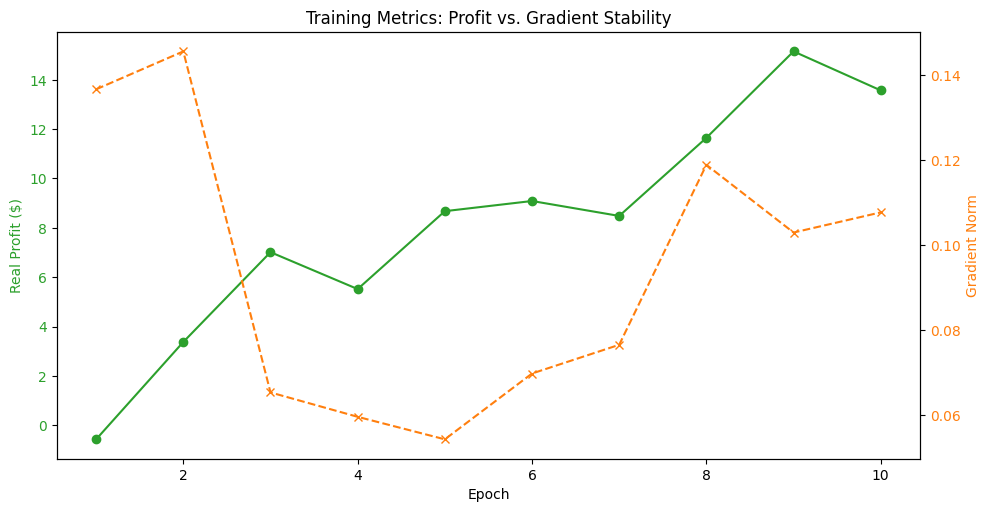

In [8]:
fig, ax1 = plt.subplots(figsize=(10, 5))

# Plot Profit
color = 'tab:green'
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Real Profit ($)', color=color)
ax1.plot(range(1, 11), profit_traj, color=color, marker='o', label='Profit')
ax1.tick_params(axis='y', labelcolor=color)

# Plot Gradients on secondary axis
ax2 = ax1.twinx()  
color = 'tab:orange'
ax2.set_ylabel('Gradient Norm', color=color)  
ax2.plot(range(1, 11), grad_traj, color=color, marker='x', linestyle='--', label='Grad Norm')
ax2.tick_params(axis='y', labelcolor=color)

fig.tight_layout()  
plt.title("Training Metrics: Profit vs. Gradient Stability")
plt.show()